# 03 — Data Quality Assessment
**Objective:** Detect missing values, duplicates, invalid timestamps, outliers and integrity problems.
**Rule:** Investigate only. No data is modified here; decisions are made in notebook 4.
**Deliverable:** Data quality report.

In [1]:
# import library
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"

In [9]:
files = {
    "customers":   "customers.csv",
    "geolocation": "geolocation.csv",
    "order_items": "order_items.csv",
    "payments":    "order_payments.csv",
    "reviews":     "order_review.csv",
    "orders":      "orders.csv",
    "products":    "products.csv",
    "sellers":     "sellers.csv",
    "translation": "product_category_name.csv",
}

missing = [f for f in files.values() if not (RAW_DIR / f).exists()]
assert not missing, f"Missing files in {RAW_DIR}: {missing}"
data = {name: pd.read_csv(RAW_DIR / f) for name, f in files.items()}
print("Loaded:", {k: v.shape for k, v in data.items()})

# --- orders ---
orders = data["orders"].copy()
order_date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                   "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in order_date_cols:
    orders[c] = pd.to_datetime(orders[c])

# --- order items ---
items = data["order_items"].copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

# --- reviews ---
reviews = data["reviews"].copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

# --- other tables ---
payments = data["payments"]
products = data["products"]
customers = data["customers"]

print("Ready:", orders.shape, items.shape, reviews.shape, payments.shape, products.shape, customers.shape)

Loaded: {'customers': (99441, 5), 'geolocation': (1000163, 5), 'order_items': (112650, 7), 'payments': (103886, 5), 'reviews': (99224, 7), 'orders': (99441, 8), 'products': (32951, 9), 'sellers': (3095, 4), 'translation': (71, 2)}
Ready: (99441, 8) (112650, 7) (99224, 7) (103886, 5) (32951, 9) (99441, 5)


In [10]:
# Cell 3: missing delivery dates by order status

orders["missing_delivered_date"] = orders["order_delivered_customer_date"].isna()
orders["missing_approved"] = orders["order_approved_at"].isna()
orders["missing_carrier"] = orders["order_delivered_carrier_date"].isna()

print("Missing dates by order status:")
display(orders.groupby("order_status")[["missing_approved", "missing_carrier", "missing_delivered_date"]].sum())

delivered_no_date = orders[(orders["order_status"] == "delivered") & orders["missing_delivered_date"]]
print("\nDelivered orders with NO customer delivery date:", len(delivered_no_date))

non_delivered_with_date = orders[(orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()]
print("Non-delivered orders WITH a customer delivery date:", len(non_delivered_with_date))
display(non_delivered_with_date["order_status"].value_counts())

Missing dates by order status:


,missing_approved,missing_carrier,missing_delivered_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609



Delivered orders with NO customer delivery date: 8
Non-delivered orders WITH a customer delivery date: 6


order_status
canceled    6
Name: count, dtype: int64

In [11]:
# Cell 4: illogical timestamp order

o = orders
checks = {
    "approved before purchase":          (o["order_approved_at"] < o["order_purchase_timestamp"]).sum(),
    "carrier pickup before approval":    (o["order_delivered_carrier_date"] < o["order_approved_at"]).sum(),
    "carrier pickup before purchase":    (o["order_delivered_carrier_date"] < o["order_purchase_timestamp"]).sum(),
    "delivered before carrier pickup":   (o["order_delivered_customer_date"] < o["order_delivered_carrier_date"]).sum(),
    "delivered before purchase":         (o["order_delivered_customer_date"] < o["order_purchase_timestamp"]).sum(),
    "estimated date before purchase":    (o["order_estimated_delivery_date"] < o["order_purchase_timestamp"]).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
approved before purchase,0
carrier pickup before approval,1359
carrier pickup before purchase,166
delivered before carrier pickup,23
delivered before purchase,0
estimated date before purchase,0


,delivery_days,estimated_days,delay_days
count,"96,470.00","96,470.00","96,470.00"
mean,12.56,23.74,-11.18
std,9.55,8.76,10.18
min,0.53,2.01,-146.02
1%,1.83,6.05,-35.14
5%,3.02,10.48,-25.94
50%,10.22,23.23,-11.95
95%,29.27,38.42,3.82
99%,46.05,50.21,18.94
max,209.63,155.14,188.98


Delivered in < 1 day:   13
Delivered in > 60 days: 306
Delivered in > 100 days: 64
Late deliveries: 8.1%


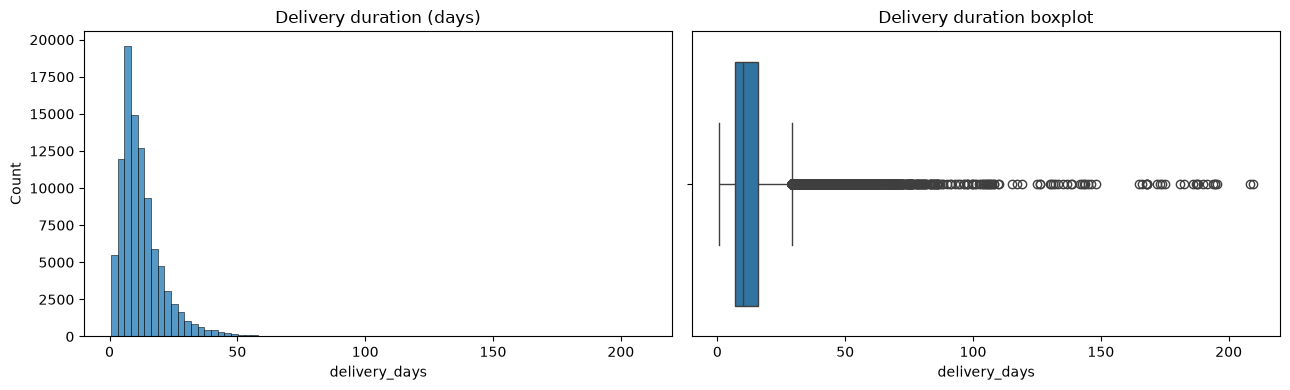

In [12]:
# Cell 5: delivery duration outliers

d = orders[orders["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"]).copy()
d["delivery_days"] = (d["order_delivered_customer_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
d["estimated_days"] = (d["order_estimated_delivery_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
d["delay_days"] = (d["order_delivered_customer_date"] - d["order_estimated_delivery_date"]).dt.total_seconds() / 86400

display(d[["delivery_days", "estimated_days", "delay_days"]].describe(percentiles=[.01, .05, .5, .95, .99]))

print("Delivered in < 1 day:  ", (d["delivery_days"] < 1).sum())
print("Delivered in > 60 days:", (d["delivery_days"] > 60).sum())
print("Delivered in > 100 days:", (d["delivery_days"] > 100).sum())
print(f"Late deliveries: {(d['delay_days'] > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(d["delivery_days"], bins=80, ax=axes[0]); axes[0].set_title("Delivery duration (days)")
sns.boxplot(x=d["delivery_days"], ax=axes[1]); axes[1].set_title("Delivery duration boxplot")
plt.tight_layout(); plt.show()

In [13]:
# Cell 6: orders without items or payments

orders_with_items = set(items["order_id"])
orders_with_pay = set(payments["order_id"])

orders["has_items"] = orders["order_id"].isin(orders_with_items)
orders["has_payment"] = orders["order_id"].isin(orders_with_pay)

print("Orders without items:   ", (~orders["has_items"]).sum())
print("Orders without payments:", (~orders["has_payment"]).sum())
print("\nStatus of orders without items:")
display(orders.loc[~orders["has_items"], "order_status"].value_counts())
print("\nOrder with no payment:")
display(orders.loc[~orders["has_payment"], ["order_id", "order_status"]])

Orders without items:    775
Orders without payments: 1

Status of orders without items:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


Order with no payment:


,order_id,order_status
30710,bfbd0f9bdef84302105ad712db648a6c,delivered


In [14]:
# Cell 7: negative, zero and extreme values

print("Items: price <= 0:        ", (items["price"] <= 0).sum())
print("Items: freight < 0:       ", (items["freight_value"] < 0).sum())
print("Items: freight == 0:      ", (items["freight_value"] == 0).sum())
print("Payments: value < 0:      ", (payments["payment_value"] < 0).sum())
print("Payments: value == 0:     ", (payments["payment_value"] == 0).sum())
print("Payments: installments=0: ", (payments["payment_installments"] == 0).sum())

display(items[["price", "freight_value"]].describe(percentiles=[.5, .95, .99, .999]))
display(payments["payment_type"].value_counts())
display(payments[payments["payment_value"] == 0].head(10))

print("\nMost expensive items (check if genuine):")
display(items.nlargest(5, "price")[["order_id", "product_id", "price", "freight_value"]])

print("\nItems where freight > price:", (items["freight_value"] > items["price"]).sum())


Items: price <= 0:         0
Items: freight < 0:        0
Items: freight == 0:       383
Payments: value < 0:       0
Payments: value == 0:      9
Payments: installments=0:  2


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
50%,74.99,16.26
95%,349.90,45.12
99%,890.00,84.52
99.9%,"2,110.00",175.59
max,"6,735.00",409.68


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.00



Most expensive items (check if genuine):


,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,"6,735.00",194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,"6,729.00",193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,"6,499.00",227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,"4,799.00",151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,"4,690.00",74.34



Items where freight > price: 4124


In [15]:
# Cell 8: payment total vs item total

item_totals = items.groupby("order_id").agg(items_price=("price", "sum"), items_freight=("freight_value", "sum")).reset_index()
item_totals["items_total"] = item_totals["items_price"] + item_totals["items_freight"]
pay_totals = payments.groupby("order_id").agg(pay_total=("payment_value", "sum"), n_payments=("payment_sequential", "max")).reset_index()

cmp = item_totals.merge(pay_totals, on="order_id", how="inner")
cmp["diff"] = cmp["pay_total"] - cmp["items_total"]

print("Orders compared:", len(cmp))
print("Exact match (within R$0.01):", (cmp["diff"].abs() <= 0.01).sum())
print("Mismatch > R$1:             ", (cmp["diff"].abs() > 1).sum())
print("Mismatch > R$10:            ", (cmp["diff"].abs() > 10).sum())
display(cmp["diff"].describe())
print(f"\nTotal payment value: R$ {cmp['pay_total'].sum():,.2f}")
print(f"Total items+freight: R$ {cmp['items_total'].sum():,.2f}")
display(cmp.loc[cmp["diff"].abs() > 10].sort_values("diff").head(8))


Orders compared: 98665
Exact match (within R$0.01): 98276
Mismatch > R$1:              249
Mismatch > R$10:             98


count   98,665.00
mean         0.03
std          1.13
min        -51.62
25%          0.00
50%          0.00
75%          0.00
max        182.81
Name: diff, dtype: float64


Total payment value: R$ 15,846,280.17
Total items+freight: R$ 15,843,409.78


,order_id,items_price,items_freight,items_total,pay_total,n_payments,diff
14628,262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,177.74,126.12,1,-51.62
97605,fd33085945f15975375cd8ec85440511,217.99,16.63,234.62,212.82,1,-21.80
42504,6e57e23ecac1ae881286657694444267,330.00,20.41,350.41,333.91,1,-16.50
25102,4154bf1348caac78152fe76e3e9c4af8,149.90,15.36,165.26,150.27,1,-14.99
42292,6dcf0aeb8b1eb4021c26e1d0e9394979,299.00,34.92,333.92,318.97,1,-14.95
5533,0e556f5eafbf3eb399290101b183b10e,49.80,45.86,95.66,81.90,1,-13.76
49461,8092da256aefda13b330290d2ca86521,103.90,11.75,115.65,105.26,1,-10.39
88603,e57d9d7eca079892fe0aee2b0cf96311,89.99,15.39,105.38,115.42,1,10.04


In [16]:
# Cell 9: multiple reviews per order

rev_counts = reviews.groupby("order_id").size()
print("Orders with more than 1 review:", (rev_counts > 1).sum())
print("Max reviews on one order:", rev_counts.max())

dup_review_ids = reviews[reviews.duplicated("review_id", keep=False)].sort_values("review_id")
print("Rows sharing a review_id:", len(dup_review_ids))
display(dup_review_ids.head(6))

print("\nOrders with no review:", (~data["orders"]["order_id"].isin(reviews["order_id"])).sum())
print("Review score distribution:")
display(reviews["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1))

Orders with more than 1 review: 547
Max reviews on one order: 3
Rows sharing a review_id: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53



Orders with no review: 768
Review score distribution:


review_score
1   11.50
2    3.20
3    8.20
4   19.30
5   57.80
Name: proportion, dtype: float64

In [17]:
# Cell 10: duplicate records and consistency

print("Duplicate geolocation rows:", data["geolocation"].duplicated().sum())
print("Duplicate customer_unique_id + zip combos:", customers.duplicated(["customer_unique_id", "customer_zip_code_prefix"]).sum())

# Same customer_unique_id in different states?
multi_state = customers.groupby("customer_unique_id")["customer_state"].nunique()
print("Customers appearing in >1 state:", (multi_state > 1).sum())

# Zip prefixes in customers/sellers missing from geolocation
geo_zips = set(data["geolocation"]["geolocation_zip_code_prefix"])
print("Customer zips not in geolocation:", (~customers["customer_zip_code_prefix"].isin(geo_zips)).sum())
print("Seller zips not in geolocation:  ", (~data["sellers"]["seller_zip_code_prefix"].isin(geo_zips)).sum())

# Geolocation points outside Brazil
g = data["geolocation"]
outside = g[(g["geolocation_lat"] > 5.3) | (g["geolocation_lat"] < -34) | (g["geolocation_lng"] < -74) | (g["geolocation_lng"] > -34)]
print("Geolocation points outside Brazil bounding box:", len(outside))

# Inconsistent text (case/spacing) in categorical columns
for col in ["customer_city", "customer_state"]:
    s = customers[col]
    print(f"{col}: {s.nunique()} unique, {s.str.strip().str.lower().nunique()} after trim/lower")

Duplicate geolocation rows: 261831
Duplicate customer_unique_id + zip combos: 3091
Customers appearing in >1 state: 39
Customer zips not in geolocation: 278
Seller zips not in geolocation:   7
Geolocation points outside Brazil bounding box: 42
customer_city: 4119 unique, 4119 after trim/lower
customer_state: 27 unique, 27 after trim/lower


month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
orders,4,324,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


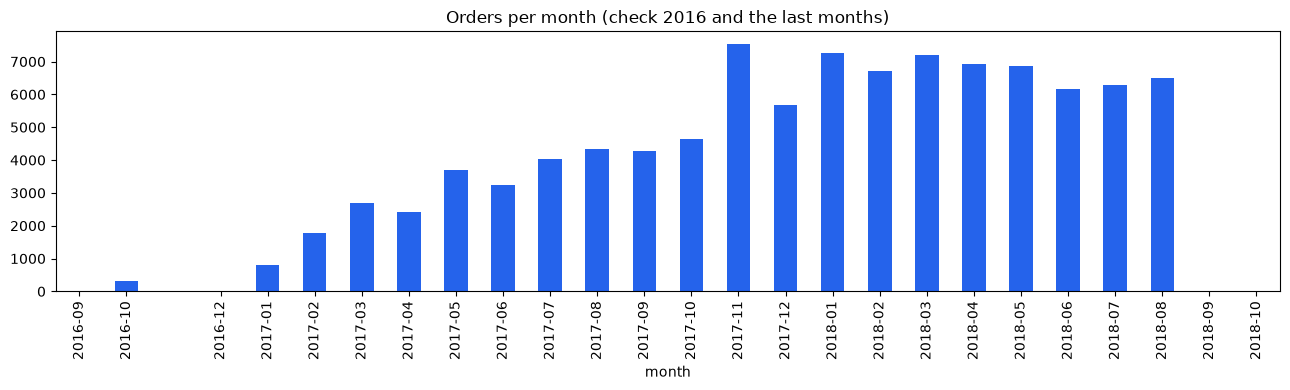

In [18]:
# Cell 11:  sparse early data and incomplete final months

monthly = (orders.assign(month=orders["order_purchase_timestamp"].dt.to_period("M"))
                 .groupby("month").size())
display(monthly.to_frame("orders").T)

fig, ax = plt.subplots(figsize=(13, 4))
monthly.plot(kind="bar", ax=ax, color="#2563eb")
ax.set_title("Orders per month (check 2016 and the last months)")
plt.tight_layout(); plt.show()

In [19]:
# Cell 12: product data quality
print("Products missing category:", products["product_category_name"].isna().sum())
print("Products with weight == 0:", (products["product_weight_g"] == 0).sum())
print("Products with missing dimensions:", products[["product_length_cm", "product_height_cm", "product_width_cm"]].isna().any(axis=1).sum())

cat_missing = products.merge(data["translation"], on="product_category_name", how="left")
untranslated = cat_missing[cat_missing["product_category_name"].notna() & cat_missing["product_category_name_english"].isna()]
print("\nCategories without English translation:")
display(untranslated["product_category_name"].value_counts())

display(products.describe().T)


Products missing category: 610
Products with weight == 0: 4
Products with missing dimensions: 2

Categories without English translation:


product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,"32,341.00",48.48,10.25,5.00,42.00,51.00,57.00,76.00
product_description_lenght,"32,341.00",771.50,635.12,4.00,339.00,595.00,972.00,"3,992.00"
product_photos_qty,"32,341.00",2.19,1.74,1.00,1.00,1.00,3.00,20.00
product_weight_g,"32,949.00","2,276.47","4,282.04",0.00,300.00,700.00,"1,900.00","40,425.00"
product_length_cm,"32,949.00",30.82,16.91,7.00,18.00,25.00,38.00,105.00
product_height_cm,"32,949.00",16.94,13.64,2.00,8.00,13.00,21.00,105.00
product_width_cm,"32,949.00",23.20,12.08,6.00,15.00,20.00,30.00,118.00


## Data quality summary

| # | Issue | Table | Count | Severity | Action (notebook 4) |
|---|-------|-------|-------|----------|---------------------|
| 1 | Delivered but no delivery date | orders | 8 | High | Exclude from delivery analysis |
| 2 | Carrier pickup before approval / before purchase | orders | 1,359 / 166 | Medium | Flag; never use as features |
| 3 | Delivered before carrier pickup | orders | 23 | Low | Flag |
| 4 | Extreme delivery duration (>60 / >100 days) | orders | 306 / 64 | Low | Keep (genuine), flag |
| 5 | Orders with no items | orders | 775 | Medium | Exclude via valid-sale rule |
| 6 | Delivered order with no payment | orders | 1 | Low | Revenue left missing |
| 7 | Payment vs items+freight mismatch > R$1 | payments/items | 249 of 98,665 (gap 0.02%) | Low | Revenue = payment_value |
| 8 | Zero-value payments / 0 installments | payments | 9 / 2 | Low | Keep zeros; installments set to 1 |
| 9 | Orders with multiple reviews | reviews | 547 | High | Keep latest per order |
| 10 | Orders with no review | orders | 768 | Medium | Leave missing |
| 11 | Duplicate geolocation rows | geolocation | 261,831 | Medium | Aggregate to one row per zip |
| 12 | Geolocation points outside Brazil | geolocation | 42 | Low | Remove |
| 13 | Zips missing from geolocation | customers / sellers | 278 / 7 | Low | Leave coordinates missing |
| 14 | Customers in more than one state | customers | 39 | Low | Use latest order's state (notebook 8) |
| 15 | Missing product category | products | 610 | Low | Fill as "unknown" |
| 16 | Untranslated categories | translation | 2 (13 products) | Low | Add manual translations |
| 17 | Product weight = 0 / missing dimensions | products | 4 / 2 | Low | Set weight to missing |
| 18 | Sparse months (2016; Sep-Oct 2018) | orders | 329 / 20 orders | Medium | Trend window Jan 2017 to Aug 2018 |